# Machine Learning Lab Task - Part 2: Classification

**Dataset:** Social Network Ads (Kaggle) - `datasets/Social_Network_Ads.csv`

**Goal:** Predict whether a user will **purchase** a product (`Purchased` = 0 or 1) after seeing a social network ad, using `Age` and `EstimatedSalary`.

**Algorithms:**
1. Logistic Regression
2. Support Vector Machine (SVM)
3. K-Nearest Neighbors (KNN)
4. Decision Tree

**Steps:** load data → EDA → preprocess → split → scale → train each model → evaluate → decision boundary → compare all models

## 1. Import Libraries

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

## 2. Load the Dataset

In [7]:
df = pd.read_csv("../datasets/Social_Network_Ads.csv")
print("Shape of dataset:", df.shape)
df.head()

Shape of dataset: (400, 5)


,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


## 3. Exploratory Data Analysis (EDA)

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   User ID          400 non-null    int64
 1   Gender           400 non-null    str  
 2   Age              400 non-null    int64
 3   EstimatedSalary  400 non-null    int64
 4   Purchased        400 non-null    int64
dtypes: int64(4), str(1)
memory usage: 15.8 KB


In [9]:
df.describe()

,User ID,Age,EstimatedSalary,Purchased
count,4.000000e+02,400.000000,400.000000,400.000000
mean,1.569154e+07,37.655000,69742.500000,0.357500
std,7.165832e+04,10.482877,34096.960282,0.479864
min,1.556669e+07,18.000000,15000.000000,0.000000
25%,1.562676e+07,29.750000,43000.000000,0.000000
50%,1.569434e+07,37.000000,70000.000000,0.000000
75%,1.575036e+07,46.000000,88000.000000,1.000000
max,1.581524e+07,60.000000,150000.000000,1.000000


In [10]:
print("Missing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Missing values:
 User ID            0
Gender             0
Age                0
EstimatedSalary    0
Purchased          0
dtype: int64

Duplicate rows: 0


### 3.1 Class distribution of the target

Purchased
0    257
1    143
Name: count, dtype: int64


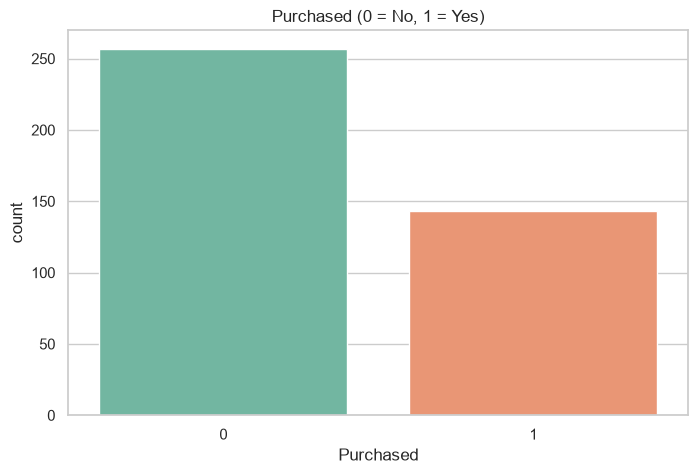

In [11]:
print(df["Purchased"].value_counts())
sns.countplot(data=df, x="Purchased", palette="Set2")
plt.title("Purchased (0 = No, 1 = Yes)")
plt.show()

### 3.2 Feature relationships

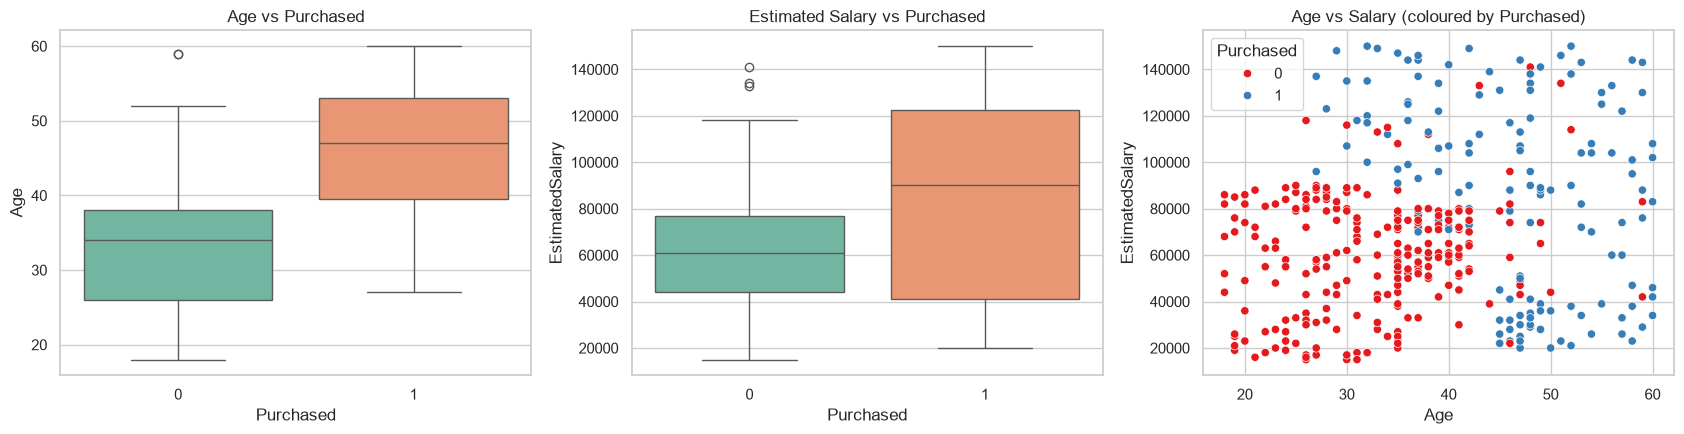

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

sns.boxplot(data=df, x="Purchased", y="Age", palette="Set2", ax=axes[0])
axes[0].set_title("Age vs Purchased")

sns.boxplot(data=df, x="Purchased", y="EstimatedSalary", palette="Set2", ax=axes[1])
axes[1].set_title("Estimated Salary vs Purchased")

sns.scatterplot(data=df, x="Age", y="EstimatedSalary", hue="Purchased", palette="Set1", ax=axes[2])
axes[2].set_title("Age vs Salary (coloured by Purchased)")

plt.tight_layout()
plt.show()

Older users and users with higher salaries are more likely to purchase. The classes overlap but follow a visible pattern.

## 4. Preprocessing

- `User ID` is just an identifier, so it is **dropped**.
- `Gender` shows little predictive value, so we use the two numeric features **`Age`** and **`EstimatedSalary`**. This also lets us draw 2-D decision boundaries.
- Features are **standardized** (zero mean, unit variance). This is essential for SVM and KNN (distance-based) and helps Logistic Regression.

In [13]:
X = df[["Age", "EstimatedSalary"]].values
y = df["Purchased"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=0, stratify=y
)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)   # fit ONLY on training data
X_test_sc = scaler.transform(X_test)

print("Training samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])

Training samples: 300
Testing samples : 100


## 5. Helper Functions

In [14]:
results = []   # stores metrics of every model for the final comparison

def evaluate_model(model, name):
    """Predict on the test set, print metrics, plot confusion matrix, store results."""
    y_pred = model.predict(X_test_sc)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    print(f"Accuracy  : {acc:.4f}")
    print(f"Precision : {prec:.4f}")
    print(f"Recall    : {rec:.4f}")
    print(f"F1-score  : {f1:.4f}\n")
    print("Classification Report:\n", classification_report(y_test, y_pred, target_names=["Not Purchased", "Purchased"]))

    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                           display_labels=["Not Purchased", "Purchased"]).plot(cmap="Blues")
    plt.title(f"Confusion Matrix — {name}")
    plt.grid(False)
    plt.show()

    results.append({"Model": name, "Accuracy": acc, "Precision": prec, "Recall": rec, "F1-score": f1})


def plot_decision_boundary(model, X_set, y_set, title):
    """Plot the decision regions of a trained model (in original, un-scaled units)."""
    X1, X2 = np.meshgrid(
        np.arange(X_set[:, 0].min() - 1, X_set[:, 0].max() + 1, 0.02),
        np.arange(X_set[:, 1].min() - 1, X_set[:, 1].max() + 1, 0.02),
    )
    Z = model.predict(np.c_[X1.ravel(), X2.ravel()]).reshape(X1.shape)

    plt.figure(figsize=(8, 6))
    plt.contourf(X1, X2, Z, alpha=0.35, cmap=ListedColormap(["#ff9999", "#99ff99"]))
    for cls, color, label in [(0, "red", "Not Purchased"), (1, "green", "Purchased")]:
        plt.scatter(X_set[y_set == cls, 0], X_set[y_set == cls, 1],
                    c=color, edgecolors="k", s=25, label=label)
    plt.title(title)
    plt.xlabel("Age (standardized)")
    plt.ylabel("Estimated Salary (standardized)")
    plt.legend()
    plt.show()

---
# Model 1 - Logistic Regression

Logistic Regression models the **probability** that a sample belongs to class 1 using the sigmoid function:

$$P(y=1|x) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x_1 + \beta_2 x_2)}}$$

If the probability ≥ 0.5, the predicted class is 1 (Purchased). Its decision boundary is a **straight line**.

In [15]:
log_reg = LogisticRegression(random_state=0)
log_reg.fit(X_train_sc, y_train)

print("Coefficients (Age, Salary):", log_reg.coef_[0].round(3))
print("Intercept:", log_reg.intercept_.round(3))

Coefficients (Age, Salary): [2.202 1.165]
Intercept: [-1.086]


Accuracy  : 0.8100
Precision : 0.7931
Recall    : 0.6389
F1-score  : 0.7077

Classification Report:
                precision    recall  f1-score   support

Not Purchased       0.82      0.91      0.86        64
    Purchased       0.79      0.64      0.71        36

     accuracy                           0.81       100
    macro avg       0.81      0.77      0.78       100
 weighted avg       0.81      0.81      0.80       100



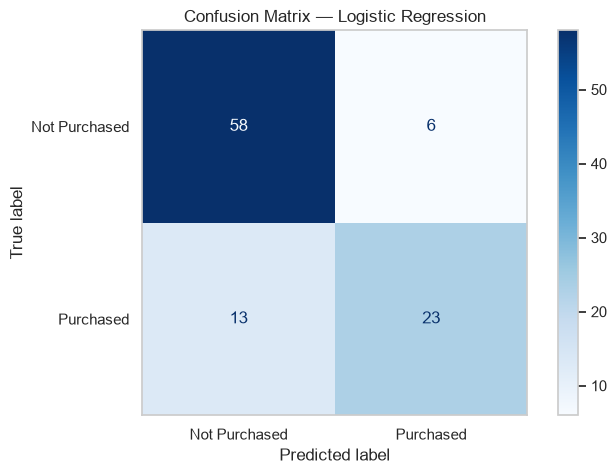

In [16]:
evaluate_model(log_reg, "Logistic Regression")

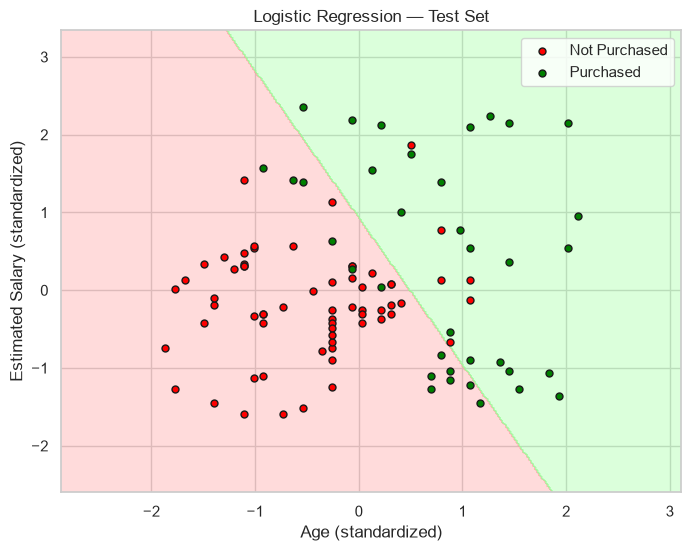

In [17]:
plot_decision_boundary(log_reg, X_test_sc, y_test, "Logistic Regression — Test Set")

---
# Model 2 - Support Vector Machine (SVM)

SVM finds the **hyperplane that maximizes the margin** between the two classes. With the **RBF kernel** it can learn a non-linear boundary.

First, compare different kernels:

In [18]:
for kernel in ["linear", "poly", "rbf", "sigmoid"]:
    m = SVC(kernel=kernel, random_state=0).fit(X_train_sc, y_train)
    print(f"Kernel = {kernel:8s} -> Test accuracy: {m.score(X_test_sc, y_test):.4f}")

Kernel = linear   -> Test accuracy: 0.8100
Kernel = poly     -> Test accuracy: 0.8600
Kernel = rbf      -> Test accuracy: 0.8900
Kernel = sigmoid  -> Test accuracy: 0.6700


Accuracy  : 0.8900
Precision : 0.8049
Recall    : 0.9167
F1-score  : 0.8571

Classification Report:
                precision    recall  f1-score   support

Not Purchased       0.95      0.88      0.91        64
    Purchased       0.80      0.92      0.86        36

     accuracy                           0.89       100
    macro avg       0.88      0.90      0.88       100
 weighted avg       0.90      0.89      0.89       100



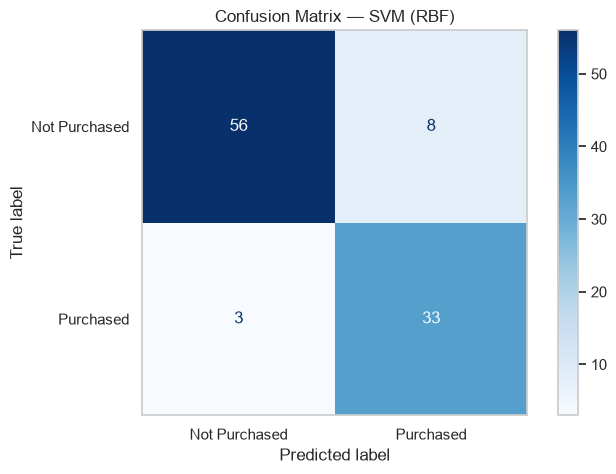

In [19]:
svm = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=0)
svm.fit(X_train_sc, y_train)
evaluate_model(svm, "SVM (RBF)")

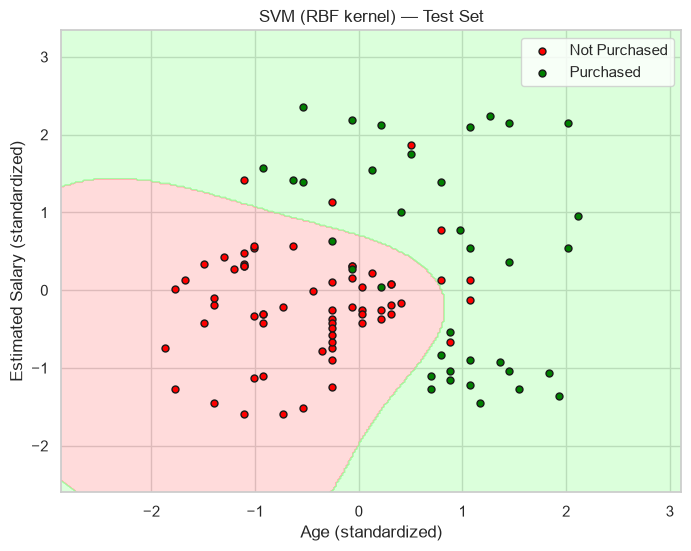

In [20]:
plot_decision_boundary(svm, X_test_sc, y_test, "SVM (RBF kernel) — Test Set")

---
# Model 3 - K-Nearest Neighbors (KNN)

KNN classifies a sample by a **majority vote of its K closest training points** (using distance). The choice of **K** matters, so we first test several values.

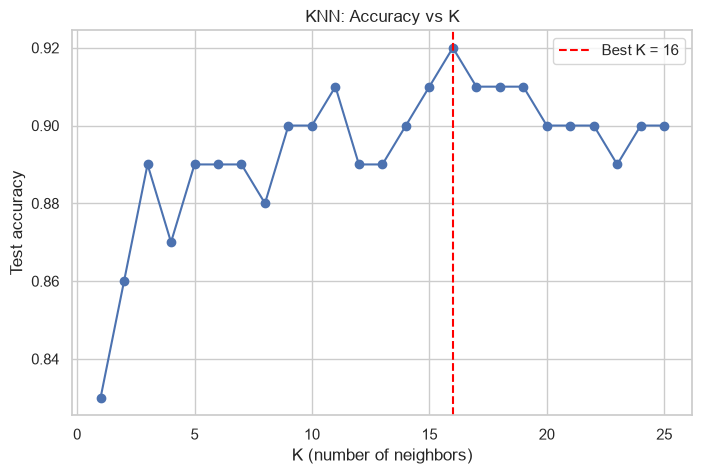

Best K: 16


In [21]:
k_values = range(1, 26)
test_acc = []
for k in k_values:
    knn_tmp = KNeighborsClassifier(n_neighbors=k).fit(X_train_sc, y_train)
    test_acc.append(knn_tmp.score(X_test_sc, y_test))

best_k = k_values[int(np.argmax(test_acc))]

plt.plot(k_values, test_acc, marker="o")
plt.axvline(best_k, color="red", linestyle="--", label=f"Best K = {best_k}")
plt.title("KNN: Accuracy vs K")
plt.xlabel("K (number of neighbors)")
plt.ylabel("Test accuracy")
plt.legend()
plt.show()

print("Best K:", best_k)

Accuracy  : 0.9200
Precision : 0.8684
Recall    : 0.9167
F1-score  : 0.8919

Classification Report:
                precision    recall  f1-score   support

Not Purchased       0.95      0.92      0.94        64
    Purchased       0.87      0.92      0.89        36

     accuracy                           0.92       100
    macro avg       0.91      0.92      0.91       100
 weighted avg       0.92      0.92      0.92       100



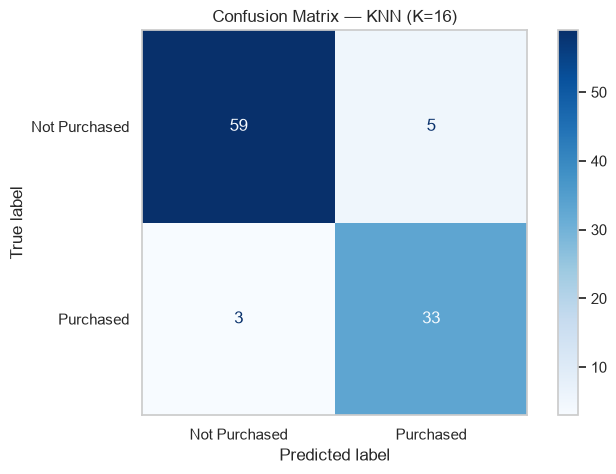

In [22]:
knn = KNeighborsClassifier(n_neighbors=best_k, metric="minkowski", p=2)   # p=2 -> Euclidean distance
knn.fit(X_train_sc, y_train)
evaluate_model(knn, f"KNN (K={best_k})")

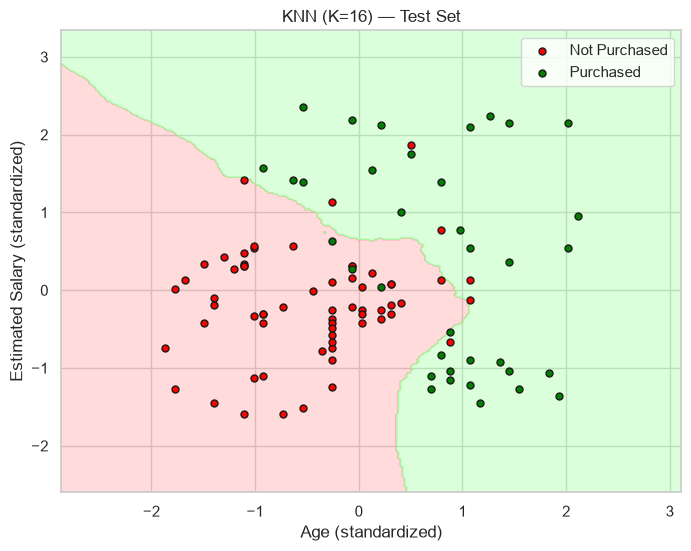

In [23]:
plot_decision_boundary(knn, X_test_sc, y_test, f"KNN (K={best_k}) — Test Set")

---
# Model 4 - Decision Tree

A Decision Tree splits the data using a series of **if/else rules** on the features, choosing splits that best separate the classes (using *entropy* or *Gini impurity*). Unrestricted trees overfit, so we limit the depth.

In [24]:
for d in [1, 2, 3, 4, 5, 6, 8, 10, None]:
    m = DecisionTreeClassifier(max_depth=d, criterion="entropy", random_state=0).fit(X_train_sc, y_train)
    print(f"max_depth = {str(d):4s} -> Train acc: {m.score(X_train_sc, y_train):.4f} | Test acc: {m.score(X_test_sc, y_test):.4f}")

max_depth = 1    -> Train acc: 0.8433 | Test acc: 0.8300
max_depth = 2    -> Train acc: 0.9200 | Test acc: 0.8900
max_depth = 3    -> Train acc: 0.9200 | Test acc: 0.8900
max_depth = 4    -> Train acc: 0.9400 | Test acc: 0.8800
max_depth = 5    -> Train acc: 0.9533 | Test acc: 0.8800
max_depth = 6    -> Train acc: 0.9667 | Test acc: 0.8800
max_depth = 8    -> Train acc: 0.9800 | Test acc: 0.8700
max_depth = 10   -> Train acc: 0.9900 | Test acc: 0.8500
max_depth = None -> Train acc: 0.9967 | Test acc: 0.8400


Accuracy  : 0.8800
Precision : 0.8158
Recall    : 0.8611
F1-score  : 0.8378

Classification Report:
                precision    recall  f1-score   support

Not Purchased       0.92      0.89      0.90        64
    Purchased       0.82      0.86      0.84        36

     accuracy                           0.88       100
    macro avg       0.87      0.88      0.87       100
 weighted avg       0.88      0.88      0.88       100



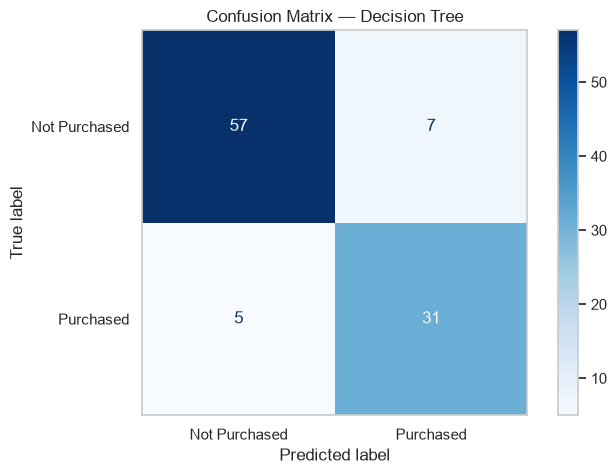

In [25]:
dtree = DecisionTreeClassifier(criterion="entropy", max_depth=4, random_state=0)
dtree.fit(X_train_sc, y_train)
evaluate_model(dtree, "Decision Tree")

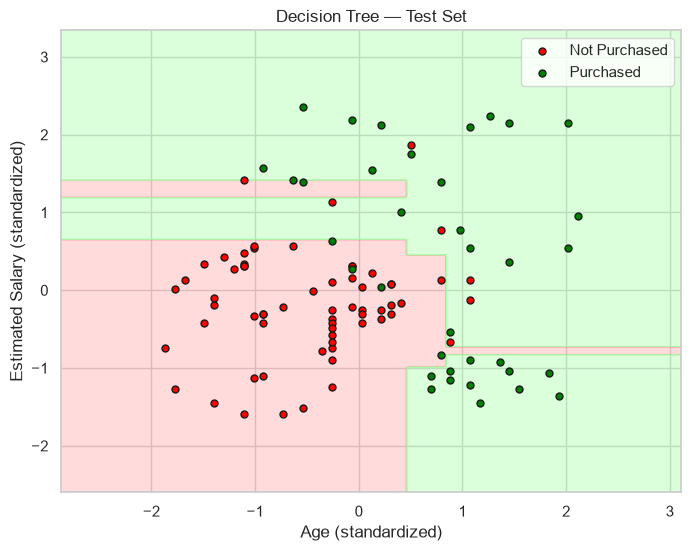

In [26]:
plot_decision_boundary(dtree, X_test_sc, y_test, "Decision Tree — Test Set")

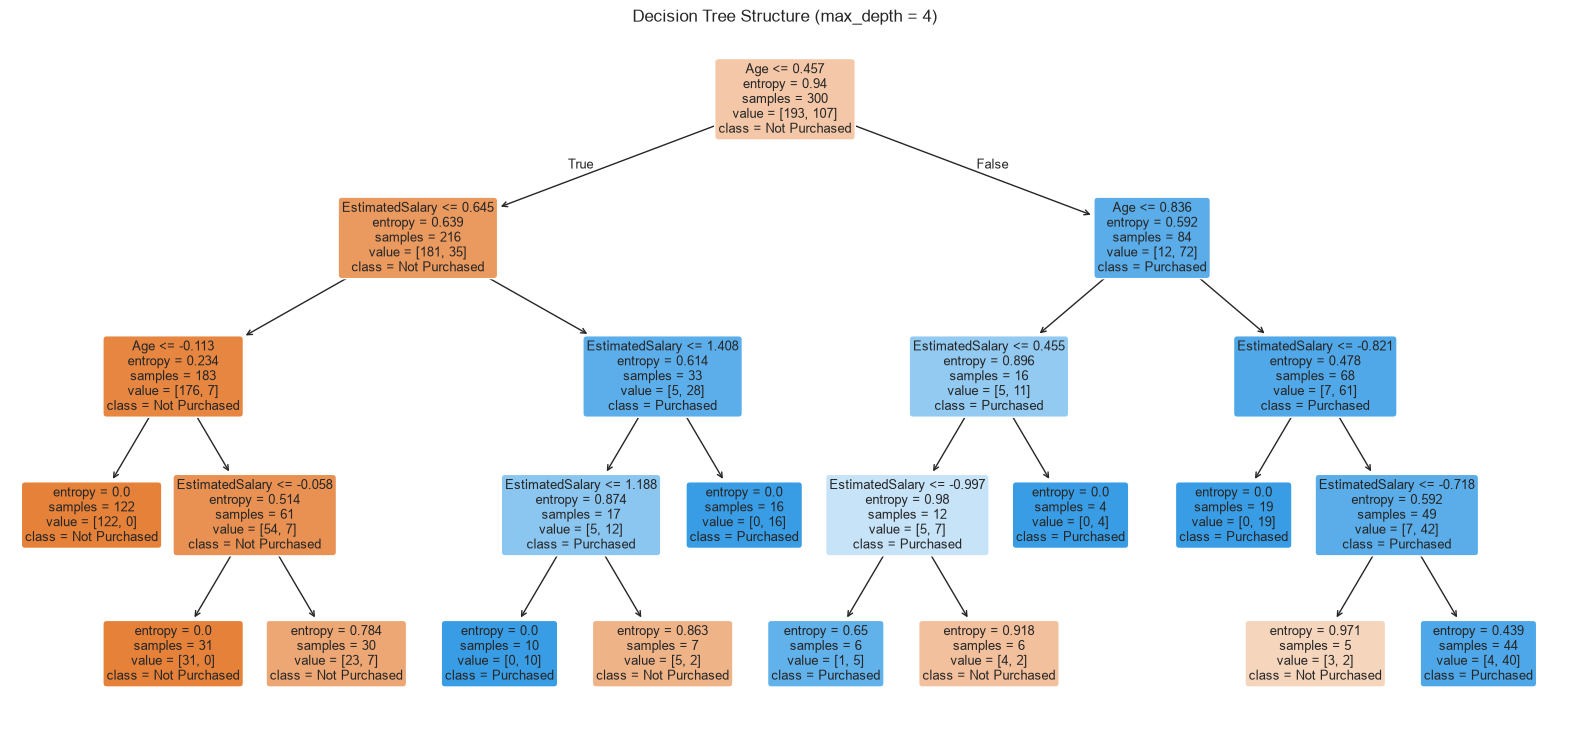

In [27]:
plt.figure(figsize=(20, 9))
plot_tree(dtree, feature_names=["Age", "EstimatedSalary"], class_names=["Not Purchased", "Purchased"],
          filled=True, rounded=True, fontsize=9)
plt.title("Decision Tree Structure (max_depth = 4)")
plt.show()

---
# Comparison of All Models

In [28]:
comparison = pd.DataFrame(results).set_index("Model").round(4)
comparison.sort_values("Accuracy", ascending=False)

,Accuracy,Precision,Recall,F1-score
Model,,,,
KNN (K=16),0.92,0.8684,0.9167,0.8919
SVM (RBF),0.89,0.8049,0.9167,0.8571
Decision Tree,0.88,0.8158,0.8611,0.8378
Logistic Regression,0.81,0.7931,0.6389,0.7077


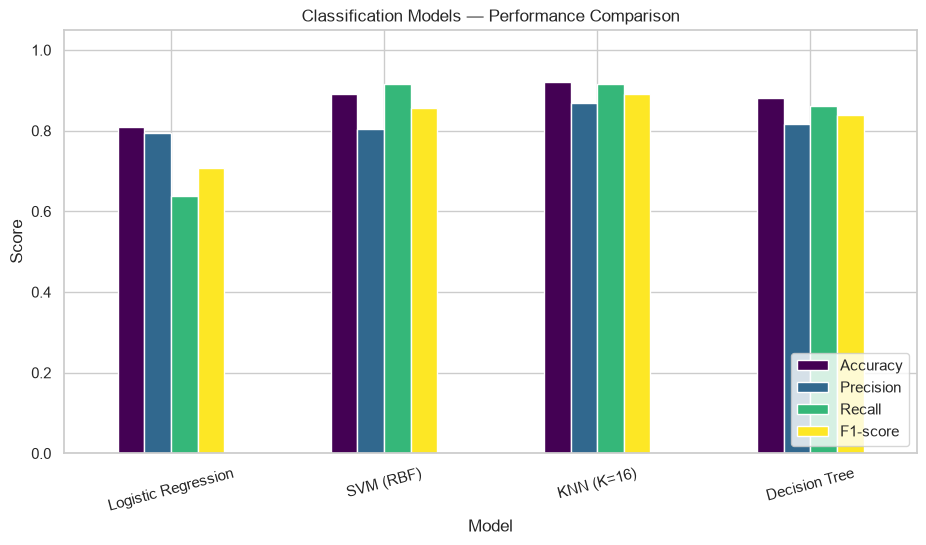

In [29]:
comparison.plot(kind="bar", figsize=(11, 5.5), rot=15, colormap="viridis")
plt.title("Classification Models — Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.legend(loc="lower right")
plt.show()

In [30]:
best = comparison["Accuracy"].idxmax()
print(f"Best model by accuracy: {best}  ({comparison.loc[best, 'Accuracy']:.4f})")

Best model by accuracy: KNN (K=16)  (0.9200)


## Conclusion

| Model | Boundary type | Notes |
|---|---|---|
| Logistic Regression | Linear (straight line) | Simple, fast, interpretable; limited on non-linear data |
| SVM (RBF) | Non-linear, smooth | Strong performance, needs feature scaling |
| KNN | Non-linear, local | Depends on K; sensitive to scaling; slower on large data |
| Decision Tree | Non-linear, axis-aligned boxes | Easy to interpret; can overfit without depth limits |

The Social Network Ads data is **not linearly separable**, so the non-linear models (SVM, KNN, Decision Tree) generally outperform the linear Logistic Regression. See the comparison table above for the exact results of this run.